# 03 · Ato 2: onde a experiência quebra?

**Projeto 1 · Tech Challenge – Fase 1 · POSTECH Data Analytics (FIAP)**
Matheus Benjamin Aquino Silva
*Trilha do projeto: o que fazer para as vendas da Olist crescerem cada vez mais?*

**Pergunta do investidor:** *qual é o risco?*

O Ato 1 (notebook 02) mostrou que o crescimento depende de clientes novos e parou em 2018. Se quase todo cliente é novo, a **primeira compra** precisa dar certo. Este notebook investiga a experiência de entrega desses clientes: quanto tempo o pedido leva, quando atrasa, o que o atraso faz com a nota e onde o problema nasce.

É a parte **diagnóstica** do estudo (*por que aconteceu?*). As hipóteses vêm dos 5 Porquês e do diagrama de Ishikawa (`docs/metodologia.md`):

| # | Hipótese | Categoria do Ishikawa |
|---|---|---|
| H2 | Atraso derruba a nota | Método / Meio ambiente |
| H3 | Distância e entrega interestadual aumentam prazo e atraso | Meio ambiente |
| H4 | Frete proporcionalmente caro pesa mais no Norte e Nordeste | Meio ambiente / Material |
| H5 | Prazo longo reduz a nota mesmo sem atraso | Método |

**Perguntas que o notebook responde**

| Bloco | Perguntas | Seção |
|---|---|---|
| Jornada | P1. Em qual etapa o pedido gasta mais tempo? · P2. O prazo prometido é cumprido? | 2 |
| Atraso no tempo | P3. Quando o atraso aumenta? | 3 |
| Atraso × nota (H2) | P4. Quantos pedidos atrasam? · P5. O atraso derruba a nota, em todas as regiões e categorias? | 4 |
| O que o atraso não explica | P6. De onde vêm as outras notas ruins? · P7. O que os clientes escrevem? | 5 |
| Distância e região (H3 e H4) | P8. Quanto a distância pesa? · P9. Como ficam prazo, atraso e frete por região? | 6 e 7 |
| Velocidade (H5) | P10. Entregar rápido importa mesmo dentro do prazo? | 8 |
| Vendedores | P11. O atraso começa no vendedor? | 9 |
| Fechamento | P12. Onde a experiência quebra, e o que isso significa para o investidor? | 10 |

**Base e definições**

| Termo | O que significa |
|---|---|
| Base | Pedidos **entregues** (D6) na janela jan/2017–ago/2018 (D1) |
| **Prazo real** | Dias entre a compra e a entrega ao cliente |
| **Prazo prometido** | Dias entre a compra e a data de entrega que a Olist informou ao cliente |
| **Atraso** | Entregar depois do dia prometido |
| **Avaliação ruim** | Nota 1 ou 2 (de 1 a 5) |
| **Mediana** | O valor do meio quando os dados são colocados em fila. Diferente da média, não é puxada por poucos pedidos que demoraram muito |

**Como ler este notebook:** cada seção abre com o objetivo, executa o código e fecha com um bloco **Leitura**, que interpreta o resultado e responde à pergunta correspondente.

## 1. Preparação
O ambiente segue o padrão dos notebooks anteriores: raiz do projeto, módulos `config`, `dados` e `viz` e formatação brasileira (`br()`). O `scipy` é opcional e só é usado no teste qui-quadrado.

As bases vêm de `data/processed/`, salvas pelo notebook 01. O CSV original de avaliações também é lido, só para buscar o texto dos comentários (seção 5); ele pode estar em `.csv` ou em `.csv.zip`.

In [1]:
# ============================================================
# IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

import sys
import re
import unicodedata
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from matplotlib.patches import Patch

# scipy é usado só no teste qui-quadrado; se não estiver instalado, o notebook segue
try:
    from scipy import stats
    TEM_SCIPY = True
except ModuleNotFoundError:
    stats = None
    TEM_SCIPY = False
    print("Aviso: scipy não instalado. Para instalar: %pip install scipy")

# ============================================================
# LOCALIZAR RAIZ DO PROJETO
# ============================================================

RAIZ = Path.cwd().resolve()

while not (RAIZ / "src").is_dir():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError("Não foi possível localizar a pasta 'src'.")
    RAIZ = RAIZ.parent

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# ============================================================
# IMPORTAR MÓDULOS DO PROJETO
# ============================================================

from src import config, dados, viz

# ============================================================
# FORMATAÇÃO BRASILEIRA
# ============================================================

def br(x, casas=0):
    """Número no padrão brasileiro: 97.905 · 20,8"""
    return (
        f"{x:,.{casas}f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )

def sinal(x):
    """'+' para valores positivos (o negativo já traz o '-')."""
    return "+" if x > 0 else ""

# ============================================================
# CONFIGURAÇÕES VISUAIS
# ============================================================

viz.aplicar_estilo()

# tabelas exibidas no padrão brasileiro (2 casas decimais)
pd.set_option("display.float_format", lambda x: br(x, 2))
pd.set_option("display.max_columns", 50)

# ============================================================
# PASTAS DO PROJETO
# ============================================================

# bases finais salvas pelo notebook 01
PASTA_PROCESSADOS = RAIZ / "data" / "processed"

# CSVs originais (usados aqui só para ler o texto dos comentários)
# aceita os 9 CSVs soltos (entrega FIAP) ou compactados em .csv.zip (repositório do GitHub)
candidatas = [RAIZ / "notebooks" / "PASTA", RAIZ / "data" / "raw"]
PASTA = next((p for p in candidatas
              if p.is_dir() and (any(p.rglob("*.csv")) or any(p.rglob("*.csv.zip")))), None)

if not PASTA_PROCESSADOS.is_dir():
    raise FileNotFoundError(f"Pasta não encontrada: {PASTA_PROCESSADOS}")
if PASTA is None:
    raise FileNotFoundError(
        "CSVs originais não encontrados. Pastas verificadas: "
        + ", ".join(str(p.relative_to(RAIZ)) for p in candidatas)
    )

print(f"Raiz do projeto: {RAIZ}")
print(f"Bases finais:    {PASTA_PROCESSADOS.relative_to(RAIZ)}")
print(f"CSVs originais:  {PASTA.relative_to(RAIZ)}")
print(f"scipy disponível: {'sim' if TEM_SCIPY else 'não'}")

Raiz do projeto: /home/claude/projeto-1-tech-challenge
Bases finais:    data/processed
CSVs originais:  data/raw
scipy disponível: sim


In [2]:
pedidos = dados.carregar("pedidos")
itens = dados.carregar("itens")

ent = pedidos[pedidos["na_janela"] & pedidos["entregue"]].copy()
ent["atrasado"] = ent["atrasado"].astype(bool)
aval = ent[ent["review_score"].notna()].copy()
aval["ruim"] = aval["avaliacao_ruim"].astype(bool)
print(f"Pedidos entregues: {len(ent):,} · com avaliação: {len(aval):,}")

Pedidos entregues: 96,203 · com avaliação: 95,560


## 2. A jornada do pedido: onde o tempo é gasto (P1 e P2)
Cada pedido passa por três etapas: **aprovação do pagamento**, **postagem** pelo vendedor e **transporte** até o cliente. A ideia é descobrir em qual delas o tempo é gasto.

Aqui é usada a **média**, e não a mediana, por um motivo prático: a média "soma". A média da aprovação + a média da postagem + a média do transporte dá exatamente a média do prazo total, o que permite dividir o prazo em pedaços.

In [3]:
etapas = ent[["dias_aprovacao", "dias_ate_postagem", "dias_transporte"]].mean()
etapas.index = ["aprovação do pagamento", "postagem pelo vendedor", "transporte"]
prazo_real = ent["dias_entrega"].mean()
prometido = ent["prazo_prometido_dias"].mean()

print(f"Prazo real médio: {prazo_real:.1f} dias · mediano: {ent['dias_entrega'].median():.1f} dias")
print(f"Prazo prometido médio: {prometido:.1f} dias · mediano: {ent['prazo_prometido_dias'].median():.1f} dias")
print(f"Folga mediana (prometido − real): {(ent['prazo_prometido_dias'] - ent['dias_entrega']).median():.1f} dias")
(etapas / etapas.sum() * 100).round(1).rename("% do tempo").to_frame()

Prazo real médio: 12.5 dias · mediano: 10.2 dias
Prazo prometido médio: 23.6 dias · mediano: 23.2 dias
Folga mediana (prometido − real): 11.8 dias


,% do tempo
aprovação do pagamento,"3,40"
postagem pelo vendedor,"22,40"
transporte,"74,20"


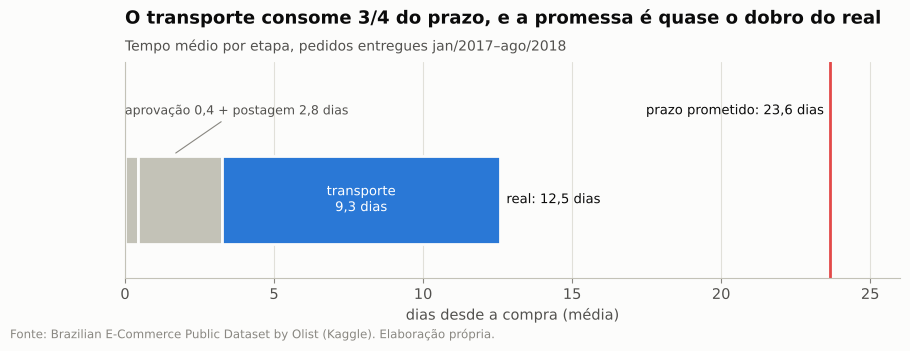

In [4]:
fig, ax = plt.subplots(figsize=(10, 2.8))
esq = 0
cores = [viz.CONTEXTO, viz.CONTEXTO, viz.DESTAQUE]
for (nome, v), cor in zip(etapas.items(), cores):
    ax.barh(0, v, left=esq, height=0.45, color=cor, edgecolor=viz.SUPERFICIE, linewidth=2)
    esq += v
ax.text(etapas.iloc[:2].sum() + etapas.iloc[2] / 2, 0, f"transporte\n{etapas.iloc[2]:.1f} dias".replace(".", ","),
        ha="center", va="center", fontsize=9.5, color="white")
ax.annotate(f"aprovação {etapas.iloc[0]:.1f} + postagem {etapas.iloc[1]:.1f} dias".replace(".", ","),
            xy=(etapas.iloc[:2].sum() / 2, 0.23), xytext=(0, 0.42), textcoords=ax.transData,
            fontsize=9, color=viz.TINTA_SECUNDARIA, ha="left", va="bottom",
            arrowprops=dict(arrowstyle="-", color=viz.TINTA_SUAVE, lw=0.8))
ax.axvline(prometido, color=viz.ALERTA, lw=2)
ax.text(prometido - 0.2, 0.42, f"prazo prometido: {prometido:.1f} dias".replace(".", ","), color=viz.TINTA,
        fontsize=9.5, va="bottom", ha="right")
ax.text(esq + 0.2, 0, f"real: {prazo_real:.1f} dias".replace(".", ","), color=viz.TINTA, fontsize=9.5, va="center")
ax.set_ylim(-0.4, 0.7); ax.set_yticks([]); ax.set_xlim(0, 26)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("dias desde a compra (média)")
viz.titulo(ax, "O transporte consome 3/4 do prazo, e a promessa é quase o dobro do real",
           "Tempo médio por etapa, pedidos entregues jan/2017–ago/2018")
viz.fonte(fig)
viz.salvar_figura(fig, "03_jornada_pedido")
plt.show()

**Leitura (P1 e P2):**

| Etapa | Tempo médio | % do prazo total |
|---|---|---|
| Aprovação do pagamento | praticamente imediata | 3,4% |
| Postagem pelo vendedor | **2,8 dias** | 22,4% |
| **Transporte** | **9,3 dias** | **74,2%** |

| Promessa × entrega | Resultado |
|---|---|
| Prazo prometido (média) | **23,6 dias** |
| Prazo real (média) | **12,5 dias** |
| Folga mediana (prometido − real) | 11,8 dias |

- O transporte é, de longe, a etapa mais longa: cerca de 3 em cada 4 dias de espera.
- A Olist promete quase o dobro do que leva para entregar.

**Implicação:** a promessa conservadora protege contra atraso, mas anunciar mais de 3 semanas de espera também pode afastar compradores. A conversão (quem desistiu de comprar) não está nesta base, então isso fica como hipótese para a Olist testar.

## 3. Atraso ao longo do tempo (P3)
O gráfico mostra, mês a mês, o prazo de entrega (barras) e o **% de pedidos atrasados** (linha). A pergunta é se o atraso é constante ou se aparece em momentos específicos.

,fev–mar/2018,resto do período
prazo prometido mediano (dias),"22,70","23,30"
prazo real mediano (dias),"14,00","9,90"
% atrasados,"16,60","5,20"


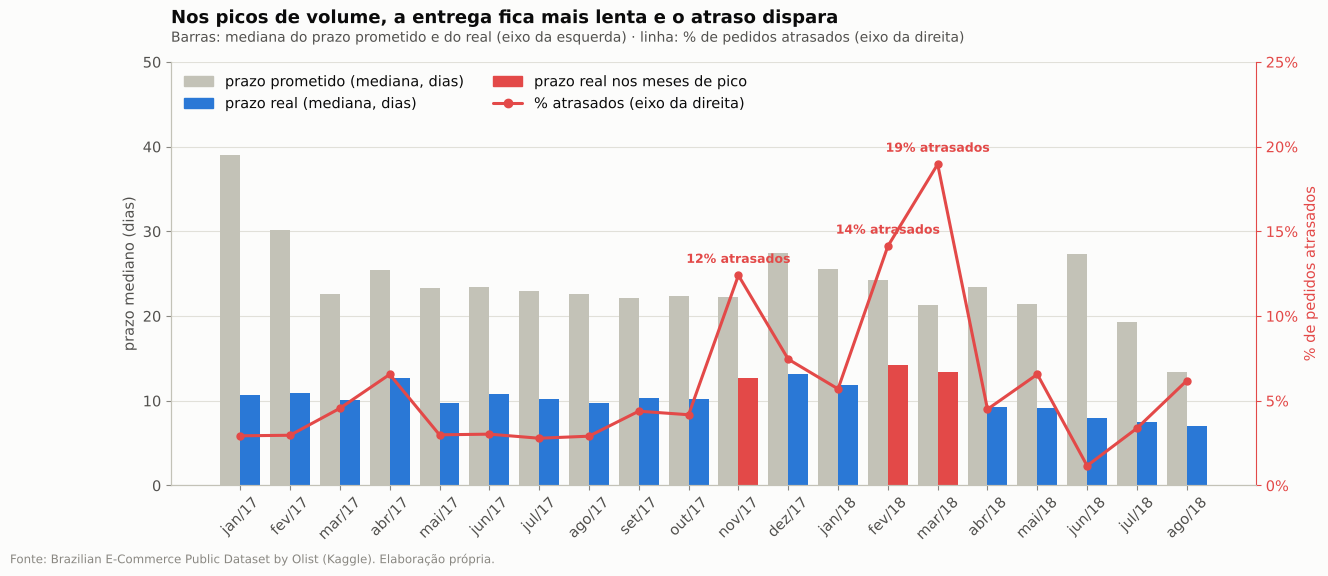

In [5]:
# ============================================================
# PRAZO (BARRAS) E % DE ATRASO (LINHA) NO MESMO GRÁFICO
# ============================================================

atraso_mes = ent.groupby("mes")["atrasado"].mean() * 100
prazo_mes = ent.groupby("mes")[["prazo_prometido_dias", "dias_entrega"]].median()

picos = atraso_mes.index.isin(pd.to_datetime(["2017-11-01", "2018-02-01", "2018-03-01"]))
x = np.arange(len(atraso_mes))
meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
rotulos = [f"{meses[d.month - 1]}/{str(d.year)[2:]}" for d in atraso_mes.index]

fig, ax = plt.subplots(figsize=(14, 5.5))

# eixo da esquerda: prazos em dias (barras)
# prazo real em vermelho nos meses de pico, azul nos demais
ax.bar(x - 0.2, prazo_mes["prazo_prometido_dias"], width=0.4, color=viz.CONTEXTO)
ax.bar(
    x + 0.2, prazo_mes["dias_entrega"], width=0.4,
    color=np.where(picos, viz.ALERTA, viz.DESTAQUE),
)
ax.set_ylabel("prazo mediano (dias)")
ax.set_ylim(0, 50)
ax.set_xticks(x, rotulos, rotation=45)

# eixo da direita: % de pedidos atrasados (linha)
ax2 = ax.twinx()
ax2.plot(x, atraso_mes.values, color=viz.ALERTA, lw=2.2, marker="o", ms=5, zorder=5)
for i in np.where(picos)[0]:
    ax2.annotate(
        f"{br(atraso_mes.iloc[i])}% atrasados", xy=(x[i], atraso_mes.iloc[i]),
        xytext=(0, 9), textcoords="offset points", ha="center",
        fontsize=9, color=viz.ALERTA, weight="bold",
    )
ax2.set_ylim(0, 25)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.set_ylabel("% de pedidos atrasados", color=viz.ALERTA)
ax2.tick_params(axis="y", colors=viz.ALERTA)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color(viz.ALERTA)

ax.legend(
    handles=[
        Patch(color=viz.CONTEXTO, label="prazo prometido (mediana, dias)"),
        Patch(color=viz.DESTAQUE, label="prazo real (mediana, dias)"),
        Patch(color=viz.ALERTA, label="prazo real nos meses de pico"),
        plt.Line2D([], [], color=viz.ALERTA, marker="o", lw=2.2, label="% atrasados (eixo da direita)"),
    ],
    loc="upper left", ncol=2,
)
viz.titulo(
    ax, "Nos picos de volume, a entrega fica mais lenta e o atraso dispara",
    "Barras: mediana do prazo prometido e do real (eixo da esquerda) · "
    "linha: % de pedidos atrasados (eixo da direita)",
)
viz.fonte(fig)
viz.salvar_figura(fig, "03_atraso_mensal")
plt.show()

# ============================================================
# NÚMEROS DE APOIO: fev–mar/2018 × resto do período
# ============================================================

fm = ent[ent["mes"].isin(pd.to_datetime(["2018-02-01", "2018-03-01"]))]
resto = ent.drop(fm.index)

comparacao_prazo = pd.DataFrame({
    "fev–mar/2018": [
        fm["prazo_prometido_dias"].median(),
        fm["dias_entrega"].median(),
        100 * fm["atrasado"].mean(),
    ],
    "resto do período": [
        resto["prazo_prometido_dias"].median(),
        resto["dias_entrega"].median(),
        100 * resto["atrasado"].mean(),
    ],
}, index=["prazo prometido mediano (dias)", "prazo real mediano (dias)", "% atrasados"])
display(comparacao_prazo.round(1))

**Leitura (P3):**

| Período | % de atraso | O que aconteceu |
|---|---|---|
| Meses normais | entre 3% e 7% | Atraso baixo |
| **Nov/2017** (Black Friday) | **12%** | Pico de vendas, pico de atraso |
| **Fev–mar/2018** | **14–19%** | O volume de pedidos estava no patamar mais alto |

Em fev–mar/2018 a promessa de prazo **não mudou** (mediana de 22,7 dias contra 23,3), mas o transporte ficou mais lento: a entrega mediana foi de 14,0 dias, contra 9,9 no resto do período.

**Conclusão:** a malha logística não acompanhou o volume. É um risco operacional que cresce junto com o negócio.

## 4. O atraso derruba a nota? (P4 e P5 · H2)
O teste é feito em três passos:
1. **Quantos atrasam:** conta-se quantos pedidos chegaram no prazo e quantos chegaram atrasados.
2. **Atraso × nota:** os atrasados são separados em faixas (1–3 dias, 4–7 dias, 8–14 dias, 15+ dias) e, em cada faixa, calcula-se o % de avaliações ruins.
3. **Prova de fogo:** a comparação é repetida **dentro** de cada região e de cada categoria, para ver se o efeito aparece em todo lugar.

In [6]:
faixas = pd.cut(aval["dias_atraso"], [-np.inf, 0, 3, 7, 14, np.inf],
                labels=["no prazo", "1–3 dias", "4–7 dias", "8–14 dias", "15+ dias"])
por_faixa = aval.groupby(faixas, observed=True).agg(pedidos=("order_id", "count"),
                                                    nota_media=("review_score", "mean"),
                                                    pct_ruim=("ruim", "mean"))
por_faixa["pct_ruim"] *= 100
por_faixa

,pedidos,nota_media,pct_ruim
dias_atraso,,,
no prazo,89182,"4,29","9,25"
1–3 dias,1851,"3,29","32,14"
4–7 dias,1748,"2,10","67,68"
8–14 dias,1446,"1,67","80,15"
15+ dias,1333,"1,72","78,32"


,pedidos,%
atrasado,,
entregues no prazo,89672,"93,20"
entregues com atraso,6531,"6,80"


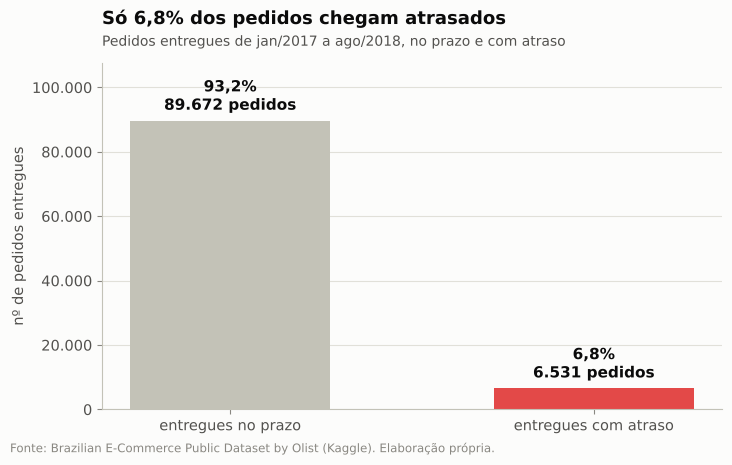

In [7]:
# ============================================================
# QUANTOS PEDIDOS ATRASAM? NO PRAZO × ATRASADOS
# ============================================================

contagem = ent["atrasado"].map({False: "entregues no prazo", True: "entregues com atraso"}).value_counts()
contagem = contagem.reindex(["entregues no prazo", "entregues com atraso"])
pct = 100 * contagem / contagem.sum()

display(pd.DataFrame({"pedidos": contagem, "%": pct.round(1)}))

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(contagem.index, contagem.values, color=[viz.CONTEXTO, viz.ALERTA], width=0.55)

for barra, n, p in zip(barras, contagem.values, pct.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2, n + contagem.max() * 0.02,
        f"{br(p, 1)}%\n{br(n)} pedidos",
        ha="center", va="bottom", fontsize=11, weight="bold", color=viz.TINTA,
    )

ax.set_ylim(0, contagem.max() * 1.2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: br(v)))
ax.set_ylabel("nº de pedidos entregues")
ax.grid(axis="x", visible=False)
viz.titulo(
    ax, f"Só {br(pct['entregues com atraso'], 1)}% dos pedidos chegam atrasados",
    "Pedidos entregues de jan/2017 a ago/2018, no prazo e com atraso",
)
viz.fonte(fig)
viz.salvar_figura(fig, "03_no_prazo_vs_atrasados")
plt.show()

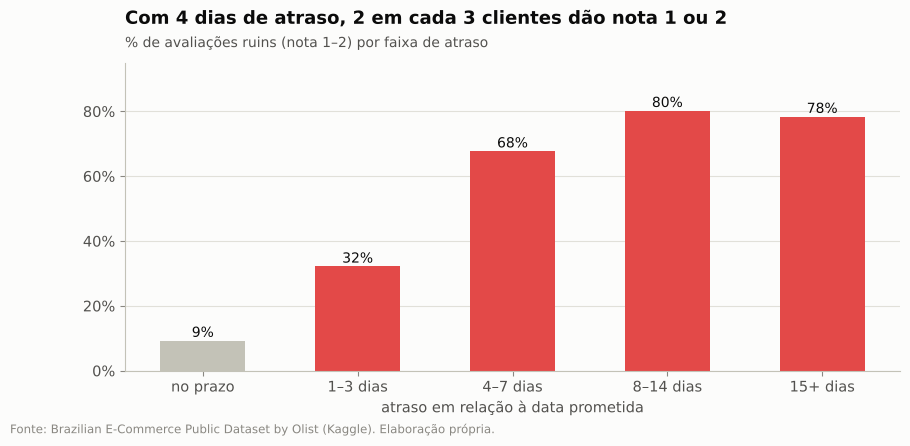

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
cores = [viz.CONTEXTO] + [viz.ALERTA] * 4
ax.bar(por_faixa.index.astype(str), por_faixa["pct_ruim"], width=0.55, color=cores)
for i, v in enumerate(por_faixa["pct_ruim"]):
    ax.text(i, v + 1.2, f"{v:.0f}%", ha="center", fontsize=10, color=viz.TINTA)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 95)
ax.set_xlabel("atraso em relação à data prometida")
viz.titulo(ax, "Com 4 dias de atraso, 2 em cada 3 clientes dão nota 1 ou 2",
           "% de avaliações ruins (nota 1–2) por faixa de atraso")
viz.fonte(fig)
viz.salvar_figura(fig, "03_atraso_nota")
plt.show()

**Por que comparar dentro de cada grupo:** a relação pode ser enganosa se o atraso estiver concentrado em regiões ou categorias que já têm notas piores por outro motivo. Por exemplo, se só os móveis atrasassem e os móveis já tivessem nota baixa, o "efeito do atraso" seria, na verdade, efeito da categoria. Por isso, atrasados e não atrasados são comparados **dentro** de cada região e de cada categoria.

O **teste qui-quadrado** responde a outra dúvida: a diferença entre atrasados e não atrasados pode ter acontecido por acaso? Um p-valor abaixo de 0,05 indica que dificilmente é acaso.

In [9]:
por_regiao = aval.pivot_table(index="regiao_cliente", columns="atrasado", values="ruim", aggfunc="mean") * 100
por_regiao.columns = ["% ruim · no prazo", "% ruim · atrasado"]

top8 = aval["categoria_principal"].value_counts().head(8).index
por_cat = aval[aval["categoria_principal"].isin(top8)].pivot_table(
    index="categoria_principal", columns="atrasado", values="ruim", aggfunc="mean") * 100
por_cat.columns = ["% ruim · no prazo", "% ruim · atrasado"]
pd.concat({"região": por_regiao, "categoria (8 maiores)": por_cat})

% ruim · no prazo  % ruim · atrasado
região                Centro-Oeste                         9,60              64,27
                      Nordeste                             9,89              64,94
                      Norte                               10,58              66,22
                      Sudeste                              9,19              61,94
                      Sul                                  8,84              59,70
categoria (8 maiores) beleza saude                         7,34              60,86
                      cama mesa banho                     11,96              64,71
                      esporte lazer                        7,44              65,02
                      informatica acessorios              11,33              61,58
                      moveis decoracao                    11,23              61,05
                      relogios presentes                   9,83              62,53
                      telefonia                           10,73              55,75
                      utilidades domesticas                8,69              62,00

In [10]:
tabela = pd.crosstab(aval["atrasado"], aval["ruim"])
qui2, p_valor, _, _ = stats.chi2_contingency(tabela)
print(f"Teste qui-quadrado (atraso × avaliação ruim): χ² = {qui2:,.0f} · p-valor = {p_valor:.1e}")

Teste qui-quadrado (atraso × avaliação ruim): χ² = 15,075 · p-valor = 0.0e+00


% ruim · no prazo  % ruim · atrasado
região                Centro-Oeste                         9,60              64,30
                      Nordeste                             9,90              64,90
                      Norte                               10,60              66,20
                      Sudeste                              9,20              61,90
                      Sul                                  8,80              59,70
categoria (8 maiores) beleza saude                         7,30              60,90
                      cama mesa banho                     12,00              64,70
                      esporte lazer                        7,40              65,00
                      informatica acessorios              11,30              61,60
                      moveis decoracao                    11,20              61,00
                      relogios presentes                   9,80              62,50
                      telefonia                           10,70              55,70
                      utilidades domesticas                8,70              62,00

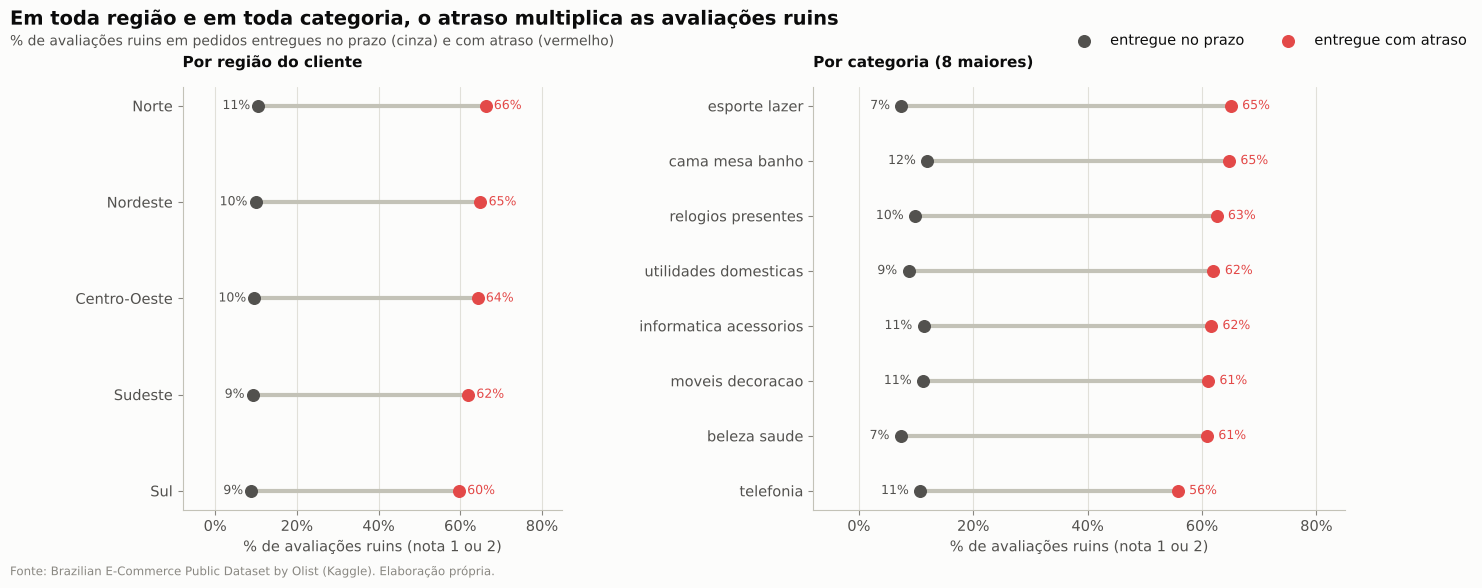

In [11]:
# ============================================================
# NOTA RUIM: NO PRAZO × ATRASADO, DENTRO DE CADA GRUPO
# ============================================================

por_regiao = aval.pivot_table(index="regiao_cliente", columns="atrasado", values="ruim", aggfunc="mean") * 100
por_regiao.columns = ["% ruim · no prazo", "% ruim · atrasado"]

top8 = aval["categoria_principal"].value_counts().head(8).index
por_cat = aval[aval["categoria_principal"].isin(top8)].pivot_table(
    index="categoria_principal", columns="atrasado", values="ruim", aggfunc="mean") * 100
por_cat.columns = ["% ruim · no prazo", "% ruim · atrasado"]

display(pd.concat({"região": por_regiao, "categoria (8 maiores)": por_cat}).round(1))

# ------------------------------------------------------------
# gráfico de halteres: bolinha cinza = no prazo, vermelha = atrasado
# ------------------------------------------------------------

fig, axs = plt.subplots(
    1, 2, figsize=(15, 5.5),
    gridspec_kw={"width_ratios": [1, 1.4], "wspace": 0.55},
)
paineis = [
    (axs[0], por_regiao, "Por região do cliente"),
    (axs[1], por_cat, "Por categoria (8 maiores)"),
]

for ax, tabela, titulo_painel in paineis:
    tabela = tabela.sort_values("% ruim · atrasado")
    y = np.arange(len(tabela))
    no_prazo = tabela["% ruim · no prazo"]
    atrasado = tabela["% ruim · atrasado"]

    ax.hlines(y, no_prazo, atrasado, color=viz.CONTEXTO, lw=3, zorder=1)
    ax.scatter(no_prazo, y, color=viz.TINTA_SECUNDARIA, s=70, zorder=3, label="entregue no prazo")
    ax.scatter(atrasado, y, color=viz.ALERTA, s=70, zorder=3, label="entregue com atraso")

    for yi, v0, v1 in zip(y, no_prazo, atrasado):
        ax.text(v0 - 2, yi, f"{br(v0)}%", ha="right", va="center", fontsize=9, color=viz.TINTA_SECUNDARIA)
        ax.text(v1 + 2, yi, f"{br(v1)}%", ha="left", va="center", fontsize=9, color=viz.ALERTA)

    ax.set_yticks(y, tabela.index)
    ax.set_xlim(-8, 85)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_xlabel("% de avaliações ruins (nota 1 ou 2)")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_title(titulo_painel, loc="left", fontsize=11, weight="bold")

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.0))
fig.suptitle(
    "Em toda região e em toda categoria, o atraso multiplica as avaliações ruins",
    x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02,
)
fig.text(
    0.01, 0.955, "% de avaliações ruins em pedidos entregues no prazo (cinza) e com atraso (vermelho)",
    fontsize=10, color=viz.TINTA_SECUNDARIA,
)
viz.fonte(fig)
viz.salvar_figura(fig, "03_atraso_por_grupo")
plt.show()

**Leitura (P4 e P5): H2 confirmada.**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| Quantos pedidos atrasam? | 6.531 de 96.203 entregues (**6,8%**) | O atraso é raro |
| O atraso derruba a nota? | Avaliações ruins: **9%** no prazo → 32% (1–3 dias) → 68% (4–7 dias) → cerca de **80%** (8+ dias) | Cada dia a mais de atraso piora a nota |
| E a nota média? | Cai de 4,3 para 1,7 | Do "bom" para o "péssimo" |
| Vale em todo lugar? | Em **todas as regiões** (de 9–11% para 60–66%) e **em todas as grandes categorias** (de 7–12% para 56–65%) | Não é efeito de região nem de produto |
| Pode ser acaso? | Teste qui-quadrado com p-valor praticamente zero | Não é acaso |

**Cuidado:** são dados observacionais, então isto é uma associação forte, e não uma prova de causa. Mas três sinais apontam para causa: o efeito cresce com a dose (mais dias de atraso, mais insatisfação), aparece em todos os segmentos e faz sentido no negócio.

## 5. Mas o atraso não explica tudo (P6 e P7)
Se só 7% dos pedidos atrasam, de onde vêm as outras avaliações ruins? A célula abaixo separa as avaliações ruins entre pedidos atrasados e entregues no prazo, e depois olha o número de itens e de vendedores de cada pedido.

In [12]:
ruins = aval[aval["ruim"]]
print(f"Avaliações ruins: {len(ruins):,} · em pedidos atrasados: {100 * ruins['atrasado'].mean():.1f}% "
      f"· em pedidos entregues no prazo: {100 * (1 - ruins['atrasado'].mean()):.1f}%")

aval["itens_pedido"] = pd.cut(aval["qtd_itens"], [0, 1, 2, np.inf], labels=["1 item", "2 itens", "3+ itens"])
cruz = aval.pivot_table(index="itens_pedido", columns="atrasado", values="ruim", aggfunc="mean", observed=True) * 100
cruz.columns = ["% ruim · no prazo", "% ruim · atrasado"]
cruz["% dos pedidos"] = aval["itens_pedido"].value_counts(normalize=True).reindex(cruz.index) * 100
vend = aval.groupby(aval["qtd_vendedores"] > 1).agg(pedidos=("order_id", "count"), pct_ruim=("ruim", "mean"))
vend.index = ["1 vendedor", "2+ vendedores"]; vend["pct_ruim"] *= 100
display_cruz = cruz.round(1)
print(vend.round(1).to_string())
display_cruz

Avaliações ruins: 12,228 · em pedidos atrasados: 32.6% · em pedidos entregues no prazo: 67.4%
               pedidos  pct_ruim
1 vendedor       94302     12,30
2+ vendedores     1258     47,10


,% ruim · no prazo,% ruim · atrasado,% dos pedidos
itens_pedido,,,
1 item,"7,50","62,10","90,10"
2 itens,"23,20","65,60","7,60"
3+ itens,"29,20","68,20","2,30"


Mesmo **entregues no prazo**, pedidos com mais de um item têm o dobro ou o triplo de avaliações ruins. Para entender o motivo, o estudo lê o que os clientes escreveram.

**Text mining** aqui é uma busca por palavras-chave nos comentários das avaliações ruins: cada comentário é passado para minúsculas e sem acento, e o código procura padrões como "faltou", "veio só um", "não recebi" ou "atrasou". Cada padrão vira um **tema** de reclamação, e a tabela mostra o % de comentários que cita cada tema.

In [13]:
# ============================================================
# LEITURA DOS COMENTÁRIOS DAS AVALIAÇÕES (CSV ORIGINAL)
# ============================================================

# procura o arquivo pelo nome dentro da PASTA (inclusive subpastas); .csv primeiro, depois .csv.zip
nome_arquivo = "olist_order_reviews_dataset.csv"
encontrados = list(PASTA.rglob(nome_arquivo)) + list(PASTA.rglob(nome_arquivo + ".zip"))
if not encontrados:
    raise FileNotFoundError(f"{nome_arquivo} não encontrado em {PASTA}")

avaliacoes = pd.read_csv(encontrados[0], parse_dates=["review_answer_timestamp"])

# D4: quando o pedido tem mais de uma avaliação, fica a mais recente
avaliacoes = (
    avaliacoes.sort_values("review_answer_timestamp")
    .drop_duplicates("order_id", keep="last")
)
print(f"Avaliações lidas de: {encontrados[0].relative_to(RAIZ)} · {br(len(avaliacoes))} pedidos avaliados")

# ============================================================
# TEXT MINING SIMPLES: TEMAS POR PALAVRA-CHAVE
# ============================================================

def normalizar(texto):
    """Minúsculas e sem acento, para a busca não depender da grafia."""
    return unicodedata.normalize("NFKD", texto.lower()).encode("ascii", "ignore").decode()

temas = {
    "falta de item / entrega parcial": r"(?:falt|apenas (?:um|1)|so (?:veio|recebi|chegou) (?:um|1)|veio (?:so|apenas)|recebi (?:so|apenas)|incomplet|metade)",
    "não recebi o produto": r"(?:nao (?:recebi|chegou|foi entregue)|ainda nao recebi|nunca chegou)",
    "atraso / demora": r"(?:atras|demor|prazo)",
    "produto errado ou diferente": r"(?:errad|diferente|trocad|outro produto)",
    "defeito / qualidade": r"(?:defeit|quebrad|danific|qualidade|nao funciona|estragad)",
}

com_texto = (
    ruins.merge(avaliacoes[["order_id", "review_comment_message"]], on="order_id")
    .dropna(subset=["review_comment_message"])
)
com_texto["texto"] = com_texto["review_comment_message"].map(normalizar)

for tema, padrao in temas.items():
    com_texto[tema] = com_texto["texto"].str.contains(padrao, regex=True)

com_texto["grupo"] = np.where(com_texto["qtd_itens"] > 1, "2+ itens", "1 item")

print(f"Avaliações ruins com comentário: {br(len(com_texto))}")

temas_por_grupo = (com_texto.groupby("grupo")[list(temas)].mean().T * 100).round(1)
temas_por_grupo

Avaliações lidas de: data/raw/olist_order_reviews_dataset.csv · 98.673 pedidos avaliados
Avaliações ruins com comentário: 9.194


grupo,1 item,2+ itens
falta de item / entrega parcial,"5,20","43,10"
não recebi o produto,"24,70","20,20"
atraso / demora,"15,80","6,10"
produto errado ou diferente,"8,80","5,30"
defeito / qualidade,"12,40","4,20"


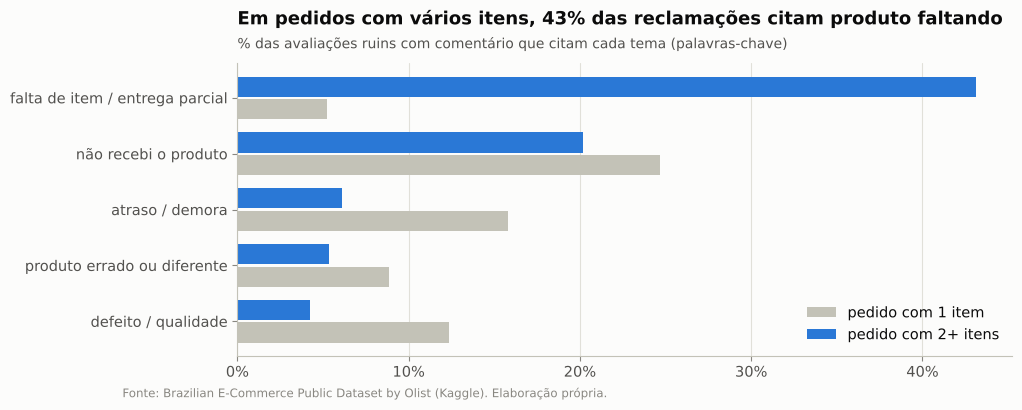

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.8))
tab = (com_texto.groupby("grupo")[list(temas)].mean().T * 100)
y = np.arange(len(tab))
ax.barh(y + 0.2, tab["1 item"], height=0.36, color=viz.CONTEXTO, label="pedido com 1 item")
ax.barh(y - 0.2, tab["2+ itens"], height=0.36, color=viz.DESTAQUE, label="pedido com 2+ itens")
ax.set_yticks(y, tab.index); ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="lower right")
viz.titulo(ax, "Em pedidos com vários itens, 43% das reclamações citam produto faltando",
           "% das avaliações ruins com comentário que citam cada tema (palavras-chave)")
viz.fonte(fig)
viz.salvar_figura(fig, "03_temas_reclamacoes")
plt.show()

**Leitura (P6 e P7): uma segunda falha de experiência.**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| De onde vêm as avaliações ruins? | **2 em cada 3 (67%) vêm de pedidos entregues no prazo** | O atraso é a principal causa evitável e mensurável, mas não a única |
| O nº de itens pesa? | No prazo, pedidos com 2 ou mais itens têm **23–29%** de avaliações ruins, contra **7,5%** com 1 item | **3 a 4 vezes mais**, mesmo sem atraso |
| E o nº de vendedores? | Pedidos com 2 ou mais vendedores chegam a **47%** de avaliações ruins | Cada vendedor posta separado |
| O que os clientes escrevem? | **43%** dos comentários desses pedidos citam item faltando ou entrega parcial, contra 5% nos pedidos de 1 item | O pedido chega "aos pedaços", sem aviso |

*Limitação:* a busca por palavras-chave é aproximada. Ela não entende negação nem contexto, e só 75% das avaliações ruins têm comentário.

review_score,1,2,3,4,5
atrasado,,,,,
no prazo,"6,60","2,60","8,10","20,40","62,30"
atrasados,"53,80","8,70","10,90","10,20","16,50"


,% dos pedidos,% ruins em cada grupo,peso real nas ruins (%),ruins a cada 1.000 pedidos,peso igualando o tamanho (%)
atrasado,,,,,
no prazo,"93,30","9,20","67,40","92,50","12,90"
atrasados,"6,70","62,40","32,60","624,20","87,10"


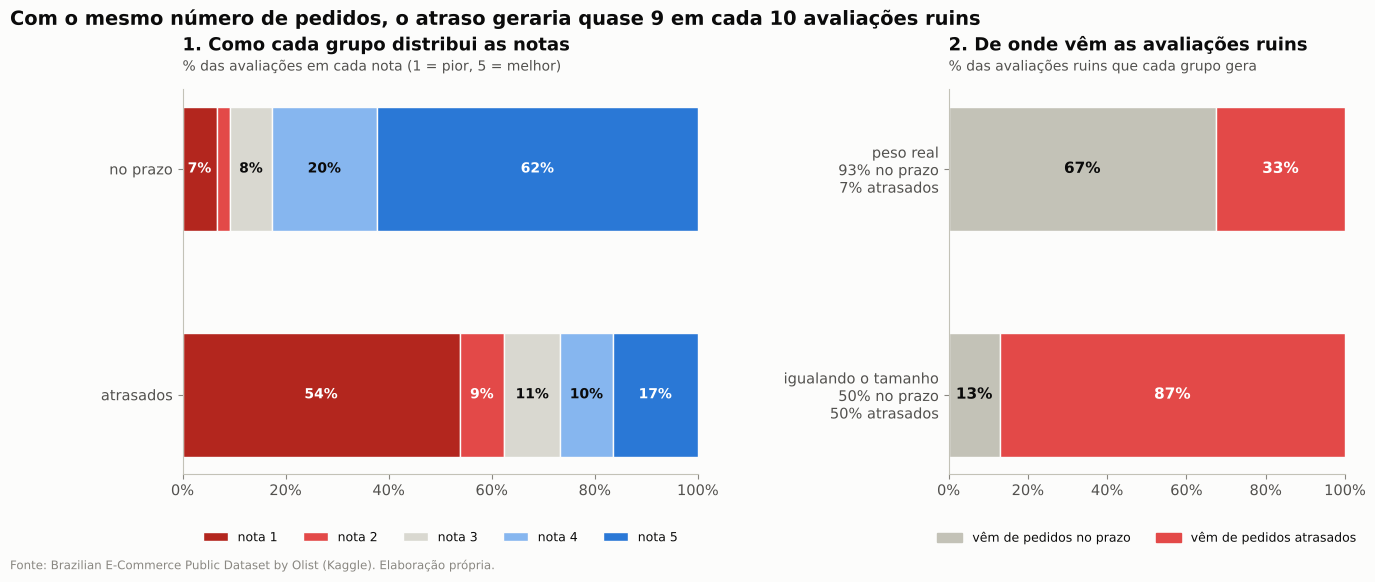

In [15]:
# ============================================================
# QUANTO O ATRASO PESA NAS NOTAS: ATRASADOS × DEMAIS
# ============================================================

grupo = aval["atrasado"].map({False: "no prazo", True: "atrasados"})
ordem = ["no prazo", "atrasados"]

# 1) distribuição das notas (1 a 5) em cada grupo, em %
dist = pd.crosstab(grupo, aval["review_score"].astype(int), normalize="index") * 100
dist = dist.reindex(ordem)
display(dist.round(1))

# 2) peso de cada grupo nas avaliações ruins: real × igualando o tamanho dos grupos
taxa_ruim = aval.groupby(grupo)["ruim"].mean().reindex(ordem) * 100        # 9% e 62%
peso = pd.DataFrame({
    "% dos pedidos": grupo.value_counts(normalize=True).reindex(ordem) * 100,
    "% ruins em cada grupo": taxa_ruim,
    # peso real: quantas das avaliações ruins vêm de cada grupo, com os tamanhos reais
    "peso real nas ruins (%)": grupo[aval["ruim"] == 1].value_counts(normalize=True).reindex(ordem) * 100,
    # igualando o tamanho: se cada grupo tivesse 1.000 pedidos, quantas ruins teria
    "ruins a cada 1.000 pedidos": taxa_ruim * 10,
})
peso["peso igualando o tamanho (%)"] = 100 * taxa_ruim / taxa_ruim.sum()
display(peso.round(1))

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.55},
)

# ---------- painel 1: barras 100% com as notas de 1 a 5 ----------
cores_nota = {1: "#b3261e", 2: viz.ALERTA, 3: "#d9d8d0", 4: "#86b6ef", 5: viz.DESTAQUE}
esquerda = np.zeros(len(dist))
for nota in [1, 2, 3, 4, 5]:
    valores = dist[nota].values
    ax1.barh(dist.index, valores, left=esquerda, color=cores_nota[nota], height=0.55,
             label=f"nota {nota}", edgecolor=viz.SUPERFICIE, linewidth=1)
    for y, (ini, v) in enumerate(zip(esquerda, valores)):
        if v >= 6:
            cor_txt = "white" if nota in (1, 2, 5) else viz.TINTA
            ax1.text(ini + v / 2, y, f"{br(v)}%", ha="center", va="center", fontsize=10,
                     color=cor_txt, weight="bold")
    esquerda += valores
ax1.invert_yaxis()
ax1.set_xlim(0, 100)
ax1.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax1.grid(axis="y", visible=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, fontsize=9)
viz.titulo(ax1, "1. Como cada grupo distribui as notas",
           "% das avaliações em cada nota (1 = pior, 5 = melhor)")

# ---------- painel 2: de onde vêm as avaliações ruins ----------
cenarios = {
    "peso real\n93% no prazo\n7% atrasados": peso["peso real nas ruins (%)"],
    "igualando o tamanho\n50% no prazo\n50% atrasados": peso["peso igualando o tamanho (%)"],
}
cor_grupo = {"no prazo": viz.CONTEXTO, "atrasados": viz.ALERTA}
for y, (nome, valores) in enumerate(cenarios.items()):
    esquerda = 0
    for g in ordem:
        v = valores[g]
        ax2.barh(y, v, left=esquerda, color=cor_grupo[g], height=0.55,
                 edgecolor=viz.SUPERFICIE, linewidth=1)
        ax2.text(esquerda + v / 2, y, f"{br(v)}%", ha="center", va="center", fontsize=11,
                 weight="bold", color="white" if g == "atrasados" else viz.TINTA)
        esquerda += v
ax2.set_yticks(range(len(cenarios)), list(cenarios))
ax2.invert_yaxis()
ax2.set_xlim(0, 100)
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.grid(axis="y", visible=False)
ax2.legend(
    handles=[Patch(color=viz.CONTEXTO, label="vêm de pedidos no prazo"),
             Patch(color=viz.ALERTA, label="vêm de pedidos atrasados")],
    loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9,
)
viz.titulo(ax2, "2. De onde vêm as avaliações ruins",
           "% das avaliações ruins que cada grupo gera")

fig.suptitle("Com o mesmo número de pedidos, o atraso geraria quase 9 em cada 10 avaliações ruins",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.04)
viz.fonte(fig)
viz.salvar_figura(fig, "03_notas_atraso_vs_demais")
plt.show()

**Leitura (gráfico acima): quanto o atraso pesa nas notas.**

| Medida | No prazo | Atrasados |
|---|---|---|
| % dos pedidos | 93,3% | 6,7% |
| Nota mais comum | **5** (62,3% dos pedidos) | **1** (53,8% dos pedidos) |
| Avaliações ruins a cada 1.000 pedidos | cerca de 92 | **cerca de 624** |
| Parte de todas as avaliações ruins | 67,4% | **32,6%** |
| Parte se os dois grupos tivessem o mesmo tamanho | 12,9% | **87,1%** |

- Os atrasados são só 6,7% dos pedidos, mas geram 32,6% das avaliações ruins: quase **5 vezes** o seu tamanho.
- A última linha "iguala" os grupos: se houvesse tantos pedidos atrasados quanto no prazo, **87%** das avaliações ruins viriam do atraso. É a medida da força do problema.

## 6. Distância: quanto mais longe, pior (P8 · H3)
A distância entre vendedor e cliente é calculada em **linha reta** entre as coordenadas dos CEPs (fórmula de haversine, que considera a curvatura da Terra). A estrada real é mais longa, mas a ordem se mantém: quem está longe continua longe. Os pedidos são separados em faixas de distância, e cada faixa recebe o prazo mediano, o % de atraso e o peso do frete.

In [16]:
faixa_dist = pd.cut(ent["distancia_km"], [0, 100, 300, 600, 1000, 2000, np.inf],
                    labels=["<100", "100–300", "300–600", "600–1 mil", "1–2 mil", ">2 mil"])
dist = ent.groupby(faixa_dist, observed=True).agg(pedidos=("order_id", "count"),
                                                  prazo_mediano=("dias_entrega", "median"),
                                                  pct_atraso=("atrasado", "mean"),
                                                  frete_mediano_pct=("frete_pct_produtos", "median"))
dist[["pct_atraso", "frete_mediano_pct"]] *= 100

um_vendedor = ent[ent["qtd_vendedores"] == 1]
mesma_uf = um_vendedor.groupby(um_vendedor["uf_cliente"] == um_vendedor["uf_vendedor_principal"]).agg(
    pedidos=("order_id", "count"), prazo_mediano=("dias_entrega", "median"), pct_atraso=("atrasado", "mean"))
mesma_uf.index = ["outro estado", "mesmo estado"]; mesma_uf["pct_atraso"] *= 100
print(mesma_uf.round(1).to_string(), "\n")
dist

              pedidos  prazo_mediano  pct_atraso
outro estado    60782          12,80        8,20
mesmo estado    34149           6,60        4,60 



,pedidos,prazo_mediano,pct_atraso,frete_mediano_pct
distancia_km,,,,
<100,17757,"5,09","4,48","17,18"
100–300,13390,"8,17","5,16","18,84"
300–600,31396,"10,32","6,77","22,97"
600–1 mil,17866,"12,51","7,13","25,28"
1–2 mil,9703,"15,35","9,52","28,42"
>2 mil,5591,"18,25","12,07","34,02"


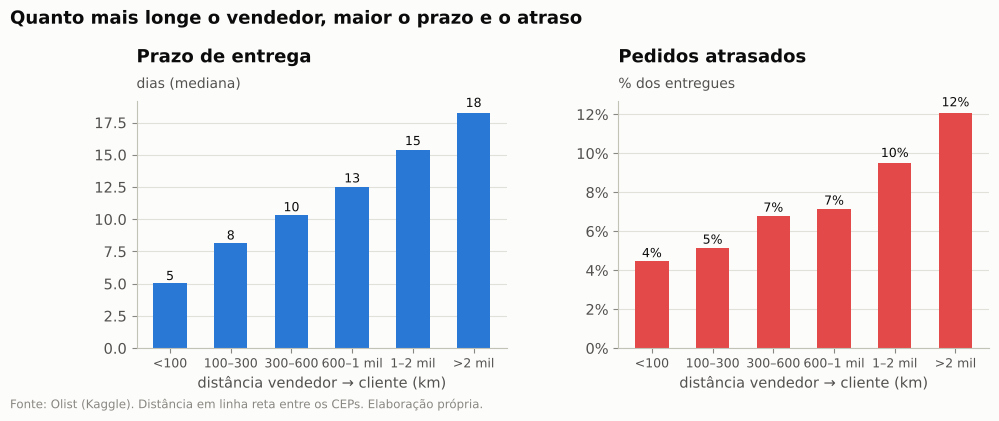

In [17]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
x = dist.index.astype(str)
a1.bar(x, dist["prazo_mediano"], width=0.55, color=viz.DESTAQUE)
a2.bar(x, dist["pct_atraso"], width=0.55, color=viz.ALERTA)
for a, col, fmt in [(a1, "prazo_mediano", "{:.0f}"), (a2, "pct_atraso", "{:.0f}%")]:
    for i, v in enumerate(dist[col]):
        a.text(i, v * 1.02 + 0.1, fmt.format(v), ha="center", fontsize=9, color=viz.TINTA)
    a.tick_params(axis="x", labelsize=9)
    a.set_xlabel("distância vendedor → cliente (km)")
viz.titulo(a1, "Prazo de entrega", "dias (mediana)")
viz.titulo(a2, "Pedidos atrasados", "% dos entregues")
a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.suptitle("Quanto mais longe o vendedor, maior o prazo e o atraso", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.0)
fig.subplots_adjust(top=0.76, wspace=0.3)
viz.fonte(fig, "Fonte: Olist (Kaggle). Distância em linha reta entre os CEPs. Elaboração própria.")
viz.salvar_figura(fig, "03_distancia")
plt.show()

**Leitura (P8): H3 confirmada.**

| Situação | Prazo mediano | % de atraso | Frete ÷ valor do produto |
|---|---|---|---|
| Até 100 km | **5 dias** | 4,5% | 17% |
| Acima de 2.000 km | **18 dias** | 12% | 34% |
| Vendedor do **mesmo estado** do cliente | 6,6 dias | 4,6% | — |
| Vendedor de **outro estado** | 12,8 dias | 8,2% | — |

- Comprar de um vendedor do mesmo estado reduz o prazo à metade e quase divide o atraso por 2.
- O frete também cresce com a distância: dobra de peso entre a faixa mais perto e a mais longe.

**Conclusão:** aproximar vendedor e cliente é a forma mais direta de entregar mais rápido.

## 7. Regiões: prazo, atraso e frete (P9 · H4)
A distância se traduz em diferença entre regiões. Aqui o estudo compara as cinco regiões e os estados em prazo prometido, prazo real, % de atraso e peso do frete. O mapa por UF mostra o prazo mediano de cada estado.

In [18]:
reg = ent.groupby("regiao_cliente").agg(pedidos=("order_id", "count"),
                                        prazo_mediano=("dias_entrega", "median"),
                                        pct_atraso=("atrasado", "mean"),
                                        frete=("valor_frete", "sum"), produtos=("valor_produtos", "sum"),
                                        nota_media=("review_score", "mean"),
                                        distancia_mediana=("distancia_km", "median"))
reg["frete_%_produto"] = 100 * reg["frete"] / reg["produtos"]
reg["pct_atraso"] *= 100
reg.drop(columns=["frete", "produtos"]).sort_values("prazo_mediano")

,pedidos,prazo_mediano,pct_atraso,nota_media,distancia_mediana,frete_%_produto
regiao_cliente,,,,,,
Sudeste,66020,"8,69","6,13","4,18","329,50","15,19"
Sul,13767,"12,11","5,92","4,19","625,64","17,69"
Centro-Oeste,5610,"13,28","6,54","4,13","863,82","17,59"
Nordeste,9015,"17,30","12,76","3,97","1.881,94","21,73"
Norte,1791,"20,15","8,60","4,03","2.373,68","22,72"


,pedidos,prazo_prometido,prazo_real,pct_atraso,nota_media,frete_%_produto,folga (dias)
regiao_cliente,,,,,,,
Sudeste,66020,"21,30","8,70","6,10","4,20","15,20","12,60"
Sul,13767,"25,90","12,10","5,90","4,20","17,70","13,80"
Centro-Oeste,5610,"26,30","13,30","6,50","4,10","17,60","13,00"
Nordeste,9015,"30,20","17,30","12,80","4,00","21,70","12,90"
Norte,1791,"36,30","20,20","8,60","4,00","22,70","16,10"


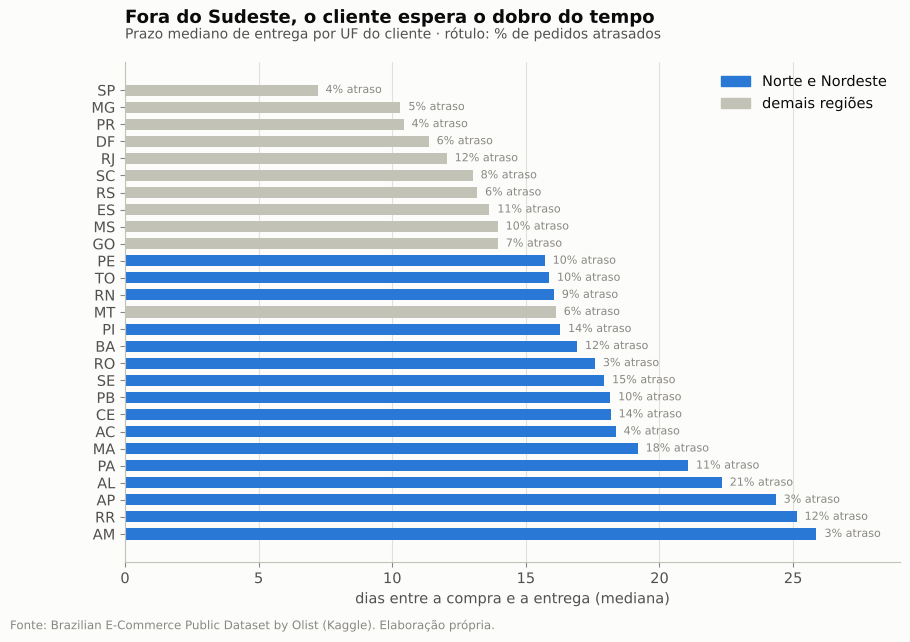

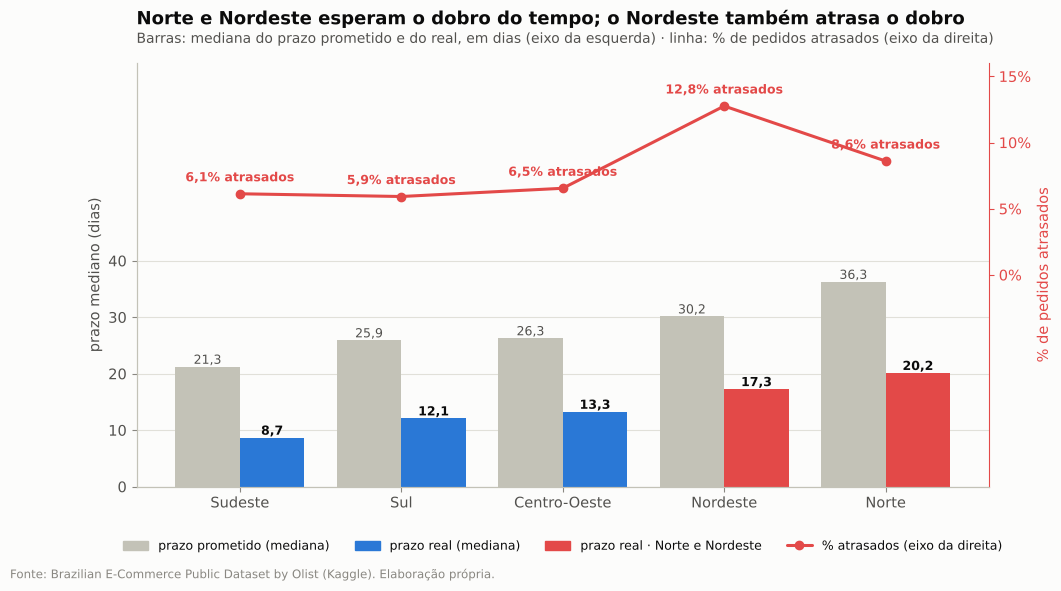

In [19]:
# ============================================================
# 1) PRAZO MEDIANO POR UF (gráfico original)
# ============================================================

uf = ent.groupby("uf_cliente").agg(pedidos=("order_id", "count"), prazo_mediano=("dias_entrega", "median"),
                                   pct_atraso=("atrasado", "mean"), nota_media=("review_score", "mean"),
                                   frete=("valor_frete", "sum"), produtos=("valor_produtos", "sum"))
uf["frete_%_produto"] = 100 * uf["frete"] / uf["produtos"]
uf["pct_atraso"] *= 100
uf = uf.drop(columns=["frete", "produtos"]).sort_values("prazo_mediano")

fig, ax = plt.subplots(figsize=(10, 6.5))
nn = uf.index.map(config.REGIAO_POR_UF).isin(["Norte", "Nordeste"])
ax.barh(uf.index, uf["prazo_mediano"], height=0.65, color=np.where(nn, viz.DESTAQUE, viz.CONTEXTO))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for i, (u, r) in enumerate(uf.iterrows()):
    ax.text(r["prazo_mediano"] + 0.3, i, f"{br(r['pct_atraso'])}% atraso", va="center", fontsize=8, color=viz.TINTA_SUAVE)
ax.legend(handles=[Patch(color=viz.DESTAQUE, label="Norte e Nordeste"), Patch(color=viz.CONTEXTO, label="demais regiões")],
          loc="upper right")
ax.set_xlim(0, 29)
ax.set_xlabel("dias entre a compra e a entrega (mediana)")
viz.titulo(ax, "Fora do Sudeste, o cliente espera o dobro do tempo",
           "Prazo mediano de entrega por UF do cliente · rótulo: % de pedidos atrasados")
viz.fonte(fig)
viz.salvar_figura(fig, "03_prazo_uf")
plt.show()

# ============================================================
# 2) POR REGIÃO: PRAZO PROMETIDO × REAL (BARRAS) E % DE ATRASO (LINHA)
# ============================================================

regiao = ent.groupby("regiao_cliente").agg(
    pedidos=("order_id", "count"),
    prazo_prometido=("prazo_prometido_dias", "median"),
    prazo_real=("dias_entrega", "median"),
    pct_atraso=("atrasado", "mean"),
    nota_media=("review_score", "mean"),
    frete=("valor_frete", "sum"),
    produtos=("valor_produtos", "sum"),
)
regiao["pct_atraso"] *= 100
regiao["frete_%_produto"] = 100 * regiao["frete"] / regiao["produtos"]
regiao["folga (dias)"] = regiao["prazo_prometido"] - regiao["prazo_real"]
regiao = regiao.drop(columns=["frete", "produtos"]).sort_values("prazo_real")
display(regiao.round(1))

x = np.arange(len(regiao))
nn_reg = regiao.index.isin(["Norte", "Nordeste"])

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(x - 0.2, regiao["prazo_prometido"], width=0.4, color=viz.CONTEXTO)
ax.bar(x + 0.2, regiao["prazo_real"], width=0.4, color=np.where(nn_reg, viz.ALERTA, viz.DESTAQUE))
for xi, (p, r) in enumerate(zip(regiao["prazo_prometido"], regiao["prazo_real"])):
    ax.text(xi - 0.2, p + 0.5, f"{br(p, 1)}", ha="center", fontsize=9, color=viz.TINTA_SECUNDARIA)
    ax.text(xi + 0.2, r + 0.5, f"{br(r, 1)}", ha="center", fontsize=9, color=viz.TINTA, weight="bold")
ax.set_xticks(x, regiao.index)
ax.set_ylabel("prazo mediano (dias)")
ax.set_ylim(0, 75)  # barras na metade de baixo, linha na de cima
ax.set_yticks(range(0, 45, 10))
ax.grid(axis="x", visible=False)

ax2 = ax.twinx()
ax2.plot(x, regiao["pct_atraso"], color=viz.ALERTA, lw=2.2, marker="o", ms=6, zorder=5)
for xi, v in zip(x, regiao["pct_atraso"]):
    ax2.annotate(f"{br(v, 1)}% atrasados", xy=(xi, v), xytext=(0, 9), textcoords="offset points",
                 ha="center", fontsize=9, color=viz.ALERTA, weight="bold",
                 bbox=dict(fc=viz.SUPERFICIE, ec="none", pad=1))
ax2.set_ylim(-16, 16)  # a linha fica na faixa de cima, sem cruzar as barras
ax2.set_yticks([0, 5, 10, 15])
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.set_ylabel("% de pedidos atrasados", color=viz.ALERTA)
ax2.tick_params(axis="y", colors=viz.ALERTA)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color(viz.ALERTA)

ax.legend(
    handles=[
        Patch(color=viz.CONTEXTO, label="prazo prometido (mediana)"),
        Patch(color=viz.DESTAQUE, label="prazo real (mediana)"),
        Patch(color=viz.ALERTA, label="prazo real · Norte e Nordeste"),
        plt.Line2D([], [], color=viz.ALERTA, marker="o", lw=2.2, label="% atrasados (eixo da direita)"),
    ],
    loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.1), fontsize=9,
)
viz.titulo(
    ax, "Norte e Nordeste esperam o dobro do tempo; o Nordeste também atrasa o dobro",
    "Barras: mediana do prazo prometido e do real, em dias (eixo da esquerda) · "
    "linha: % de pedidos atrasados (eixo da direita)",
)
viz.fonte(fig)
viz.salvar_figura(fig, "03_prazo_regiao")
plt.show()

**Leitura (P9) · gráfico por estado: H4 confirmada.**

| Destaque | Resultado | Interpretação |
|---|---|---|
| Prazo no Sudeste | **8,7 dias** (mediana) | Referência |
| Prazo no Nordeste e no Norte | **17,3** e **20,2 dias** | O dobro ou mais |
| Frete | **22–23%** do valor do produto no Norte e Nordeste, contra **15%** no Sudeste | Comprar de longe sai mais caro |
| Atraso no Nordeste | **12,8%**, contra 6,1% no Sudeste, e a pior nota média (3,97) | O dobro de atraso |
| Piores estados em atraso | **AL (22%), MA (18%), SE (15%), PI e CE (14%)** | Todos no Nordeste |
| Alerta à parte: **RJ** | 2º maior mercado, perto de SP, mas com 12% de atraso (quase 3 vezes o de SP e o de MG, 4,5–4,6%) e nota média 3,97 | Problema que não é só distância |

Isso fecha o raciocínio do Ato 1: a baixa penetração no Norte e Nordeste tem uma explicação operacional plausível, **prazo longo, frete caro e mais atraso**.

**Leitura (P9) · tabela por região:**

| Região | Prazo prometido (mediana) | Prazo real (mediana) | Folga | % atrasados | Frete / valor do produto |
|---|---|---|---|---|---|
| Sudeste | 21,3 dias | **8,7 dias** | 12,6 dias | 6,1% | 15,2% |
| Sul | 25,9 dias | 12,1 dias | 13,8 dias | 5,9% | 17,7% |
| Centro-Oeste | 26,3 dias | 13,3 dias | 13,0 dias | 6,5% | 17,6% |
| Nordeste | 30,2 dias | **17,3 dias** | 12,9 dias | **12,8%** | 21,7% |
| Norte | 36,3 dias | **20,2 dias** | 16,1 dias | 8,6% | 22,7% |

| O que comparar | O que aparece |
|---|---|
| **Prazo** | O cliente do Nordeste espera o dobro do tempo do Sudeste (17,3 contra 8,7 dias); o do Norte, mais que o dobro (20,2) |
| **Promessa** | A Olist já promete prazos mais longos para quem está longe (36 dias no Norte contra 21 no Sudeste). A folga entre o prometido e o real é parecida em todas as regiões (12 a 16 dias) |
| **Atraso** | Mesmo com promessa mais longa, o Nordeste atrasa o dobro do Sudeste (12,8% contra 6,1%). No Norte, a promessa mais folgada segura o atraso em 8,6%, mas ao custo de anunciar mais de um mês de espera |
| **Frete** | Pesa 22–23% do valor do produto no Norte e no Nordeste, contra 15% no Sudeste |

**Conclusão (H4 confirmada):** quem compra no Norte e no Nordeste espera o dobro, paga proporcionalmente mais frete e, no Nordeste, ainda recebe com o dobro de atraso. Isso ajuda a explicar a baixa penetração dessas regiões vista no notebook 02: **a maior oportunidade de crescimento é justamente onde a experiência de compra é pior.**

## 8. Velocidade importa mesmo dentro do prazo (P10 · H5)
Aqui entram **só os pedidos entregues no prazo**. Assim o atraso sai da conta, e sobra a pergunta: entre clientes que receberam no prazo, quem recebeu mais rápido dá nota melhor?

,pedidos,nota_media,pct_ruim
dias_entrega,,,
até 5,13357,"4,45","7,13"
5–10,32655,"4,37","8,10"
10–15,23168,"4,28","9,27"
15–20,11676,"4,17","11,05"
20–30,7414,"3,99","13,70"
30+,912,"3,67","21,49"


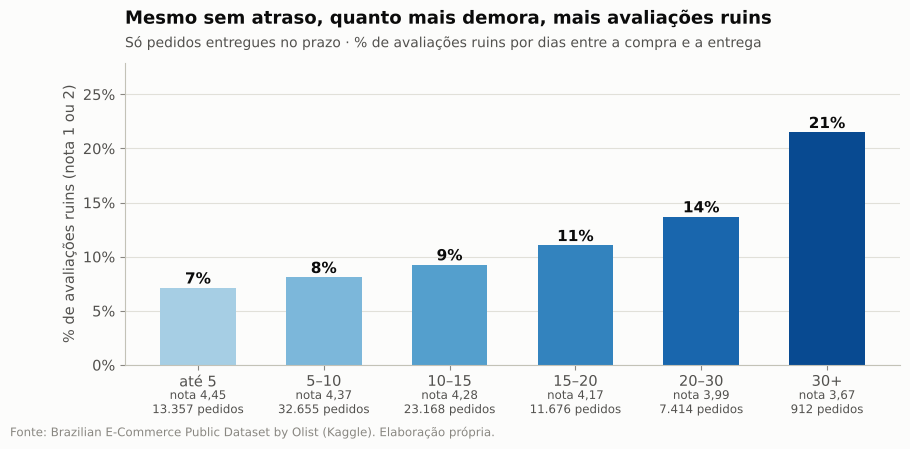

In [20]:
# ============================================================
# VELOCIDADE IMPORTA MESMO DENTRO DO PRAZO? (H5)
# ============================================================

no_prazo = aval[~aval["atrasado"]]
faixa_real = pd.cut(no_prazo["dias_entrega"], [0, 5, 10, 15, 20, 30, np.inf],
                    labels=["até 5", "5–10", "10–15", "15–20", "20–30", "30+"])
vel = no_prazo.groupby(faixa_real, observed=True).agg(pedidos=("order_id", "count"),
                                                      nota_media=("review_score", "mean"),
                                                      pct_ruim=("ruim", "mean"))
vel["pct_ruim"] *= 100
display(vel)

# ------------------------------------------------------------
# gráfico: % de avaliações ruins por velocidade (só pedidos no prazo)
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4.8))
# tons de azul que escurecem conforme a entrega demora mais
tons = plt.cm.Blues(np.linspace(0.35, 0.9, len(vel)))
barras = ax.bar(vel.index.astype(str), vel["pct_ruim"], color=tons, width=0.6)

for barra, (_, linha) in zip(barras, vel.iterrows()):
    x_centro = barra.get_x() + barra.get_width() / 2
    ax.text(x_centro, linha["pct_ruim"] + 0.4, f"{br(linha['pct_ruim'])}%",
            ha="center", fontsize=11, weight="bold", color=viz.TINTA)
    ax.text(x_centro, -2.2, f"nota {br(linha['nota_media'], 2)}\n{br(linha['pedidos'])} pedidos",
            ha="center", va="top", fontsize=8.5, color=viz.TINTA_SECUNDARIA)

ax.set_ylim(0, vel["pct_ruim"].max() * 1.3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("% de avaliações ruins (nota 1 ou 2)")
ax.set_xlabel("")
ax.grid(axis="x", visible=False)
viz.titulo(
    ax, "Mesmo sem atraso, quanto mais demora, mais avaliações ruins",
    "Só pedidos entregues no prazo · % de avaliações ruins por dias entre a compra e a entrega",
)
fig.subplots_adjust(bottom=0.25)
viz.fonte(fig)
viz.salvar_figura(fig, "03_velocidade_no_prazo")
plt.show()

**Leitura (P10): H5 confirmada (efeito moderado).**

| Prazo real (só pedidos no prazo) | Nota média | % de avaliações ruins |
|---|---|---|
| Até 5 dias | **4,45** | 7% |
| 20–30 dias | **3,99** | 14% |

**Conclusão:** cumprir a promessa não basta; o cliente também valoriza **rapidez**. Isso reforça a recomendação de aproximar vendedor e cliente.

## 9. Vendedores: onde o atraso começa (P11)
Cada item tem um **prazo-limite de postagem**: a data até a qual o vendedor precisa entregar o pacote à transportadora. A seção verifica duas coisas:
1. o que acontece com o atraso quando o vendedor posta **depois** desse limite;
2. se o atraso está espalhado entre todos os vendedores ou concentrado em alguns (só vendedores com 30 ou mais pedidos, para a taxa ser estável).

In [21]:
limite_postagem = itens.groupby("order_id")["shipping_limit_date"].max()
ent = ent.join(limite_postagem, on="order_id")
ent["postou_tarde"] = ent["order_delivered_carrier_date"] > ent["shipping_limit_date"]
print(f"Pedidos postados depois do prazo-limite do vendedor: {100 * ent['postou_tarde'].mean():.1f}%")
print(f"  atraso quando o vendedor posta tarde:  {100 * ent.loc[ent['postou_tarde'], 'atrasado'].mean():.1f}%")
print(f"  atraso quando o vendedor posta no prazo: {100 * ent.loc[~ent['postou_tarde'], 'atrasado'].mean():.1f}%")
print(f"  parcela dos atrasos com postagem tardia: {100 * ent.loc[ent['atrasado'], 'postou_tarde'].mean():.1f}%")

vendedores = ent.groupby("vendedor_principal").agg(pedidos=("order_id", "count"), pct_atraso=("atrasado", "mean"))
vendedores = vendedores[vendedores["pedidos"] >= 30]
corte = vendedores["pct_atraso"].quantile(0.9)
piores = vendedores[vendedores["pct_atraso"] >= corte]
atrasos = vendedores["pedidos"] * vendedores["pct_atraso"]
print(f"\nVendedores com 30+ pedidos: {len(vendedores)} (cobrem {100 * vendedores['pedidos'].sum() / len(ent):.0f}% dos pedidos)")
print(f"10% piores em atraso: {len(piores)} vendedores · {100 * piores['pedidos'].sum() / vendedores['pedidos'].sum():.1f}% dos pedidos "
      f"· {100 * atrasos[piores.index].sum() / atrasos.sum():.1f}% dos atrasos "
      f"· taxa de atraso {100 * atrasos[piores.index].sum() / piores['pedidos'].sum():.1f}% "
      f"vs {100 * atrasos.drop(piores.index).sum() / vendedores.drop(piores.index)['pedidos'].sum():.1f}% dos demais")

Pedidos postados depois do prazo-limite do vendedor: 8.9%
  atraso quando o vendedor posta tarde:  21.1%
  atraso quando o vendedor posta no prazo: 5.4%
  parcela dos atrasos com postagem tardia: 27.7%

Vendedores com 30+ pedidos: 619 (cobrem 83% dos pedidos)
10% piores em atraso: 62 vendedores · 6.1% dos pedidos · 14.9% dos atrasos · taxa de atraso 16.7% vs 6.2% dos demais


**Leitura (P11):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| Quantos pedidos são postados depois do limite? | **8,9%** | Quase 1 em cada 10 |
| O que isso faz com o atraso? | Atraso de **21%** quando posta tarde, contra **5%** quando posta no prazo | A chance de atraso **quadruplica** |
| O atraso está concentrado? | Os **10% de vendedores com mais atraso** fazem 6% dos pedidos, mas respondem por **15% dos atrasos** | Poucos vendedores pesam muito |

**Conclusão:** é um problema **gerenciável**, com SLA (prazo combinado) de postagem e um ranking de desempenho dos vendedores.

## 10. Conclusão do Ato 2

**Pergunta do investidor:** *qual é o risco?* O Ato 1 mostrou que o crescimento depende de clientes novos. Este notebook mostra onde a experiência desses clientes quebra e quanto isso custa em satisfação.

**Resposta curta:** a experiência quebra em **dois pontos**: o **atraso**, raro mas devastador, e o **pedido com vários itens**, que gera insatisfação mesmo quando chega no prazo.

### 10.1 Ponto de quebra 1: o atraso

| O que foi medido | Resultado |
|---|---|
| Frequência | Só **6,8%** dos pedidos entregues chegam atrasados |
| Efeito na nota | A chance de nota ruim vai de **9%** (no prazo) para **62%** (atrasado), quase **7 vezes** maior |
| Efeito por dias de atraso | 1–3 dias: 32% · 4–7 dias: 68% · 8+ dias: ~80% de notas ruins |
| Distribuição das notas | No prazo, a nota mais comum é 5 (62%); com atraso, passa a ser 1 (54%) |
| Peso nas avaliações ruins | 7% dos pedidos geram **33%** das avaliações ruins (4,9x o seu tamanho); com grupos de mesmo tamanho, seriam **87%** |
| Consistência | O efeito é o mesmo em **todas** as regiões e categorias: não é distorção de grupo |

**Onde o atraso nasce:**

| Origem | Evidência |
|---|---|
| Picos de volume | 12% em nov/2017 (Black Friday) e 14–19% em fev–mar/2018. A promessa não mudou; a entrega ficou mais lenta (mediana de 14,0 contra 9,9 dias) |
| Distância e região | Nordeste: entrega em 17,3 dias e **12,8% de atraso**, o dobro do Sudeste (8,7 dias e 6,1%). Norte: 20,2 dias. Frete de 22–23% do valor do produto, contra 15% no Sudeste |
| Vendedores | Postagem fora do prazo-limite quadruplica o atraso (21% contra 5%). Os 10% piores vendedores fazem 6% dos pedidos e 15% dos atrasos |

### 10.2 Ponto de quebra 2: o pedido com vários itens

- **2 em cada 3 avaliações ruins (67%) vêm de pedidos entregues no prazo.** O atraso é a principal causa evitável e mensurável, mas não a única.
- Pedidos com 2 ou mais itens têm **3 a 4 vezes mais avaliações ruins mesmo no prazo** (23–29%, contra 7,5% nos pedidos de 1 item). Com mais de um vendedor, chegam a **47%**.
- Nos comentários desses pedidos, **43% citam item faltando ou entrega parcial**: o pedido chega em partes, sem aviso ao cliente.

### 10.3 Hipóteses

| Hipótese | Resultado |
|---|---|
| H2: atraso derruba a nota | ✅ **Confirmada:** de 9% para 62% de avaliações ruins (até ~80% com 8+ dias), consistente em regiões e categorias |
| H3: distância aumenta prazo e atraso | ✅ **Confirmada:** até 100 km, 5 dias e 4,5% de atraso; acima de 2.000 km, 18 dias e 12% |
| H4: frete mais caro no Norte e Nordeste | ✅ **Confirmada:** 22–23% do valor do produto, contra 15% no Sudeste; o Nordeste ainda atrasa o dobro |
| H5: prazo longo reduz a nota mesmo sem atraso | ✅ **Confirmada (efeito moderado):** no prazo, de 7% de notas ruins (até 5 dias) para 14% (20–30 dias) |
| *Nova:* pedido com vários itens gera insatisfação | ✅ **Encontrada na exploração (KDD):** 3–4x mais avaliações ruins, mesmo no prazo |

### 10.4 O que isso significa para o investidor

| Alavanca | Por quê | Efeito estimado |
|---|---|---|
| **Reduzir o atraso** | Maior efeito por pedido e causas identificáveis (picos, regiões, vendedores) | Cortar o atraso pela metade reduziria as avaliações ruins em cerca de **14%** |
| **Avisar e consolidar pedidos com vários itens** | Responsável por boa parte das notas ruins de pedidos entregues no prazo | Ataca a fatia que o atraso não explica |
| **Melhorar a logística no Norte e Nordeste** | Prazo e frete piores na região que é a maior oportunidade de crescimento (Ato 1) | Destrava a expansão geográfica |

*Limitação:* os dados são observacionais, então as relações encontradas são associações. A força do efeito, o padrão dose-resposta e a consistência em todos os segmentos indicam que o atraso é causa provável, mas o impacto das ações deve ser confirmado com testes controlados.

**Próximo passo:** `04_retencao_rfm.ipynb`. Se a experiência ruim derruba a nota, a pergunta seguinte é: **ela também impede o cliente de voltar?** É a ligação entre o Ato 2 (experiência) e o Ato 3 (recompra), que explica por que o crescimento depende tanto de clientes novos.